In [ ]:
# cell 1 — mount Drive and sanity checks
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# quick list to confirm your project folder is visible
!ls -la "/content/drive/MyDrive/MMOTU-Transfer-Learning" || true

# Python packages (installs if missing)
!pip install -q segmentation_models_pytorch albumentations


Mounted at /content/drive
total 506861
drwx------ 2 root root     4096 Dec  8 09:03  checkpoints_classification
drwx------ 2 root root     4096 Nov 29 06:25  data
drwx------ 2 root root     4096 Nov 29 06:52  .git
-rw------- 1 root root       66 Nov 29 06:52  .gitattributes
drwx------ 2 root root     4096 Dec  2 08:58  masks_pred
-rw------- 1 root root   387930 Dec  8 08:54  MMOTU_Classification_4_channels.ipynb
-rw------- 1 root root    77646 Dec  8 10:01  MMOTU_Classification_using_Original_images.ipynb
-rw------- 1 root root   361551 Dec  4 11:05  MMOTU_Classification_with_original_and_mask
-rw------- 1 root root   157809 Dec  4 11:04 'MMOTU _classification_with_predicted_masks_only.ipynb'
-rw------- 1 root root 44817099 Dec  6 06:55 'mmotu_classifier_cropped_best (1).pth'
-rw------- 1 root root 44815435 Dec  3 18:35 'mmotu_classifier_cropped_best (2).pth'
-rw------- 1 root root 44802891 Dec  3 09:35 'mmotu_classifier_cropped_best (3).pth'
-rw------- 1 root root 44817099 Dec  8 08:4

In [ ]:
# cell 2 — imports and paths
import os
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
import torchvision.models as models

# ---------- Paths (use the paths you gave) ----------
PROJECT_PATH = "/content/drive/MyDrive/MMOTU-Transfer-Learning"
DATA_PATH = f"{PROJECT_PATH}/data/MMOTU"
OTU2D_PATH = f"{DATA_PATH}/OTU_2d"

TRAIN_CLS = f"{OTU2D_PATH}/train_cls.txt"   # file with lines: "123.JPG 4"
VAL_CLS   = f"{OTU2D_PATH}/val_cls.txt"
IMAGES_DIR = f"{OTU2D_PATH}/images"         # folder with JPG images

# Checkpoints / models to save in Drive
CHECKPOINT_DIR = f"{PROJECT_PATH}/checkpoints_classification"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(PROJECT_PATH, "mmotu_classifier_fullimage_best.pth")
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "mmotu_classifier_checkpoint.pth")

# ---------- Training hyperparams ----------
BATCH_SIZE = 8
NUM_WORKERS = 2
NUM_CLASSES = 8
EPOCHS = 50
LEARNING_RATE = 1e-4
EARLY_STOPPING_PATIENCE = 7

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
# quick path check
print("Exists TRAIN_CLS:", os.path.exists(TRAIN_CLS))
print("Exists VAL_CLS:  ", os.path.exists(VAL_CLS))
print("Images dir exists:", os.path.exists(IMAGES_DIR))


Device: cuda
Exists TRAIN_CLS: True
Exists VAL_CLS:   True
Images dir exists: True


### Check class imbalance

In [ ]:
import numpy as np
from collections import Counter

def read_class_distribution(list_file):
    labels = []
    with open(list_file, "r") as f:
        for line in f:
            _, label = line.strip().split()
            labels.append(int(label))
    return Counter(labels)

train_dist = read_class_distribution(TRAIN_CLS)
val_dist   = read_class_distribution(VAL_CLS)

print("TRAIN CLASS DISTRIBUTION:", train_dist)
print("VAL CLASS DISTRIBUTION:  ", val_dist)


TRAIN CLASS DISTRIBUTION: Counter({2: 228, 0: 226, 5: 180, 1: 153, 6: 71, 3: 57, 4: 47, 7: 38})
VAL CLASS DISTRIBUTION:   Counter({0: 110, 2: 108, 5: 87, 1: 66, 6: 33, 3: 31, 4: 19, 7: 15})


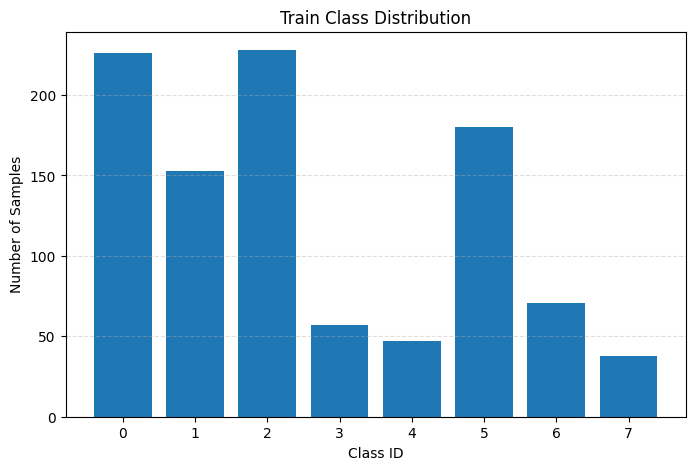

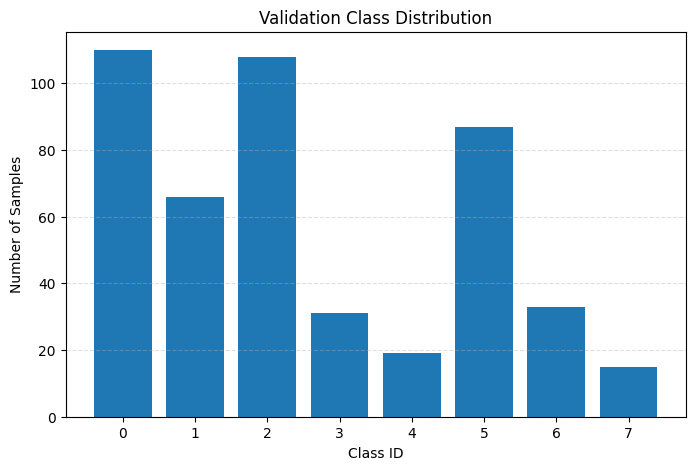

In [ ]:
import matplotlib.pyplot as plt

# Assuming you already computed:
# train_counts = Counter(train_labels)
# val_counts   = Counter(val_labels)

# Convert counters into sorted lists
train_classes = sorted(train_dist.keys())
train_values  = [train_dist[c] for c in train_classes]

val_classes = sorted(val_dist.keys())
val_values  = [val_dist[c] for c in val_classes]

# ------------------------------
# PLOT TRAIN DISTRIBUTION
# ------------------------------
plt.figure(figsize=(8,5))
plt.bar(train_classes, train_values)
plt.title("Train Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Samples")
plt.xticks(train_classes)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

# ------------------------------
# PLOT VAL DISTRIBUTION
# ------------------------------
plt.figure(figsize=(8,5))
plt.bar(val_classes, val_values)
plt.title("Validation Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Samples")
plt.xticks(val_classes)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()


In [ ]:
# cell 3 — albumentations transforms for full images
# Training: augmentation helps generalization (flip, rotate, brightness, etc.)
train_transform = A.Compose([
    A.Resize(256, 256),                      # model input size
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=20, p=0.4),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),  # ImageNet stats
    ToTensorV2()
])

# Validation: deterministic (resize + normalize)
val_transform = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2()
])


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# cell 4 — dataset class (reads "image_name.JPG label" per line)
class MMOTUFullImageDataset(Dataset):
    """Full-image classification dataset. Returns (image_tensor, label)."""
    def __init__(self, list_file, images_dir, transform=None):
        self.images_dir = images_dir
        self.transform = transform
        self.samples = []
        # Read file lines, allow variable whitespace
        with open(list_file, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 2:
                    continue
                img_name = parts[0]
                label = int(parts[1])
                self.samples.append((img_name, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_name, label = self.samples[idx]
        img_path = os.path.join(self.images_dir, img_name)
        # Load BGR, convert to RGB
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img is None:
            # fallback: return zero image (so training doesn't crash) and label - handle later
            img = np.zeros((256,256,3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        # Apply augmentation / normalization -> returns PyTorch tensor CHW
        if self.transform:
            img = self.transform(image=img)["image"]
        else:
            # fallback: manual
            img = cv2.resize(img, (256,256)).astype("float32") / 255.0
            img = (img - np.array([0.485,0.456,0.406])) / np.array([0.229,0.224,0.225])
            img = torch.tensor(img).permute(2,0,1).float()
        return img, label


In [ ]:
# cell 5 — create datasets and dataloaders
train_dataset = MMOTUFullImageDataset(TRAIN_CLS, IMAGES_DIR, transform=train_transform)
val_dataset   = MMOTUFullImageDataset(VAL_CLS, IMAGES_DIR, transform=val_transform)




### Integrating class weighting and weighted sampling to handle class imbalance

### Computing class weights

In [ ]:
# -------------------------------
# Compute class weights for CrossEntropyLoss
# -------------------------------
from collections import Counter
import torch

# Get training label counts
train_dist = read_class_distribution(TRAIN_CLS)
train_counts = [train_dist[i] for i in range(NUM_CLASSES)]

# Inverse frequency for weights
class_weights = [1.0 / c for c in train_counts]

# Normalize (optional)
total = sum(class_weights)
class_weights = [w / total * NUM_CLASSES for w in class_weights]

# Convert to PyTorch tensor on the device
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", class_weights)

# Use in loss
criterion = nn.CrossEntropyLoss(weight=class_weights)


Class weights: tensor([0.3535, 0.5222, 0.3504, 1.4018, 1.7000, 0.4439, 1.1254, 2.1027],
       device='cuda:0')


Weighted Random Sampler for Training DataLoader

In [ ]:
from torch.utils.data import WeightedRandomSampler, DataLoader

# Extract labels from training dataset
train_labels = [label for _, label in train_dataset.samples]

# Compute sample weights: inverse of class frequency
sample_weights = [1.0 / train_counts[label] for label in train_labels]

# Create sampler
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Create DataLoader using the sampler
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Validation loader remains standard
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Weighted train loader ready!")


Weighted train loader ready!


### Defining the model

In [ ]:
# Load pretrained ResNet18
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Modify classifier for 8 classes
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# Move to GPU/CPU
model = model.to(device)
print("Model ready:", model)


Model ready: ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inp

### Define Optimizer and Scheduler

In [ ]:
# Optimizer
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Scheduler: reduce LR on plateau (optional but helpful)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',       # maximize validation accuracy
    factor=0.5,       # reduce LR by factor
    patience=3,       # wait epochs before reducing

)


### Define Training and Validation Loops

#### Training Function

In [ ]:
def train_one_epoch(epoch):
    model.train()
    running_loss = 0.0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch} [Train]"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch} | Train Loss: {epoch_loss:.4f}")


#### Validation Function

In [ ]:
def validate(epoch):
    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch} [Val]"):
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            total_correct += (preds == labels).sum().item()
            total_samples += labels.size(0)

    acc = total_correct / total_samples
    print(f"Epoch {epoch} | Val Accuracy: {acc:.4f}")
    return acc


### Training Loop with Early Stopping and Checkpointing

In [ ]:
best_val_acc = 0.0
epochs_no_improve = 0
EARLY_STOPPING_PATIENCE = 25
EPOCHS=100

for epoch in range(1, EPOCHS + 1):
    # Train
    train_one_epoch(epoch)

    # Validate
    val_acc = validate(epoch)

    # Update scheduler
    scheduler.step(val_acc)

    # Check for improvement
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"--> New best val acc: {best_val_acc:.4f}. Model saved.")
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    # Early stopping
    if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping triggered after {epoch} epochs.")
        break

print(f"\nTraining complete. Best Val Accuracy = {best_val_acc:.4f}")


Epoch 1 [Train]: 100%|██████████| 125/125 [00:11<00:00, 10.79it/s]


Epoch 1 | Train Loss: 0.0960


Epoch 1 [Val]: 100%|██████████| 59/59 [00:04<00:00, 13.87it/s]


Epoch 1 | Val Accuracy: 0.6972
--> New best val acc: 0.6972. Model saved.


Epoch 2 [Train]: 100%|██████████| 125/125 [00:12<00:00,  9.70it/s]


Epoch 2 | Train Loss: 0.0944


... (138 outputs left out)

Epoch 37 [Train]: 100%|██████████| 125/125 [00:10<00:00, 11.48it/s]


Epoch 37 | Train Loss: 0.0826


Epoch 37 [Val]: 100%|██████████| 59/59 [00:04<00:00, 12.09it/s]

Epoch 37 | Val Accuracy: 0.7122
Early stopping triggered after 37 epochs.

Training complete. Best Val Accuracy = 0.7186


### Testing/Inference

In [ ]:
# Load best weights
model.load_state_dict(torch.load(BEST_MODEL_PATH))
model.eval()

# Example: predict one image
img, label = val_dataset[0]           # get one sample
img = img.unsqueeze(0).to(device)     # add batch dimension
with torch.no_grad():
    output = model(img)
    pred_class = torch.argmax(output, dim=1).item()
print("True label:", label, "Predicted:", pred_class)

True label: 5 Predicted: 5
